# Customer Churn Prediction: Project Analysis

This notebook documents the full analytical workflow behind the Streamlit dashboard: data understanding, cleaning, feature engineering, exploratory analysis, model training and evaluation, and retention scoring. Each step is shown with its code, its output, and an interpretation.

The notebook uses the same utility modules as the app (`utils/preprocessing.py`, `utils/features.py`, `utils/charts.py`), so the numbers here match what the dashboard shows.

**Dataset:** IBM Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`), 7,043 customers, 21 columns.

## 0. Setup

In [1]:
import os
import sys
import inspect
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, PROJECT_ROOT)
DATA_PATH = os.path.join(PROJECT_ROOT, "data", "WA_Fn-UseC_-Telco-Customer-Churn.csv")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Project root:", PROJECT_ROOT)
print("Data file exists:", os.path.isfile(DATA_PATH))

Project root: /home/claude/fp_churn
Data file exists: True


## 1. Data Understanding (Task 1)

### 1.1 Shape, data types, and missing values

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print()
print("Data types:")
print(df_raw.dtypes.to_string())
print()
print("Missing values (isnull):", int(df_raw.isnull().sum().sum()))

Shape: 7,043 rows x 21 columns

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str

Missing values (isnull): 0


**Interpretation.** The file has no `NaN` values, but `TotalCharges` is stored as text (`object`) rather than a number. That is a sign that some entries are not plain numbers. The next cell checks which ones.

### 1.2 Hidden problems: blank strings and duplicates

In [3]:
blank_mask = df_raw["TotalCharges"].astype(str).str.strip() == ""
print(f"Blank or whitespace-only TotalCharges rows: {int(blank_mask.sum())}")
print(f"Duplicate rows: {int(df_raw.duplicated().sum())}")
print(f"Duplicate customerID values: {int(df_raw['customerID'].duplicated().sum())}")
print()
print("Rows with blank TotalCharges:")
display(df_raw.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Blank or whitespace-only TotalCharges rows: 11
Duplicate rows: 0
Duplicate customerID values: 0

Rows with blank TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Interpretation.** There are 11 blank `TotalCharges` values. All of them belong to customers with `tenure = 0`, meaning they have not yet completed a billing cycle, so their total charge is genuinely zero. The data has no duplicate rows and no duplicate customer IDs, so every row is one unique customer.

### 1.3 Descriptive statistics and target distribution

In [4]:
print("Numeric columns (raw file):")
display(df_raw.describe().T)
print()
print("Categorical columns (raw file):")
display(df_raw.describe(include="object").T)
print()
print("Churn distribution:")
print(df_raw["Churn"].value_counts().to_string())
print(f"Churn rate: {(df_raw['Churn'] == 'Yes').mean() * 100:.2f}%")

Numeric columns (raw file):


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75



Categorical columns (raw file):


/tmp/ipykernel_238/1673707266.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_raw.describe(include="object").T)


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095



Churn distribution:
Churn
No     5174
Yes    1869
Churn rate: 26.54%


### 1.4 Understanding questions

**Q1. What does one row represent?**
One customer account. `customerID` is unique across all 7,043 rows, so the unit of analysis is the customer.

**Q2. What is the target, and how balanced is it?**
The target is `Churn` (Yes/No). About 26.5% of customers churned. The classes are imbalanced, so accuracy alone is misleading: a model that always predicts "No churn" would be about 73.5% accurate while catching no churners. Evaluation therefore relies on recall, precision, ROC-AUC, and the precision-recall curve.

**Q3. Which columns need cleaning before modeling?**
`TotalCharges` needs conversion from text to number, with the 11 blank rows handled as described above. The Yes/No text columns also need whitespace and case normalization.

**Q4. Which columns could leak the outcome?**
`Churn` and its binary encoding `Churn_Binary` are the target and must never be model inputs. The feature functions in `utils/features.py` are checked for this in Section 3.

**Q5. Which fields requested in the rubric are not in this dataset?**
The dataset has no satisfaction score, NPS, complaint count, support-ticket count, late-payment count, referral count, region, or last-interaction date. Section 7 lists these and explains how the project handles them.

## 2. Data Cleaning (Task 2)

In [5]:
from utils.preprocessing import load_clean_data

df_clean, report = load_clean_data(DATA_PATH)
print(f"Clean shape: {df_clean.shape}")
print(f"Blank TotalCharges set to 0.0: {report['n_blank_tc']}")
print(f"Other coercion failures set to 0.0: {report['n_other_tc_errors']}")
print(f"Overall churn rate: {report['churn_rate'] * 100:.2f}%")
print()
print("Range checks:")
for note in report["range_notes"]:
    print("  " + note)
print()
print("Cleaned data types:")
print(df_clean.dtypes.to_string())

Clean shape: (7043, 21)
Blank TotalCharges set to 0.0: 11
Other coercion failures set to 0.0: 0
Overall churn rate: 26.54%

Range checks:
  tenure range: [0, 72] months — expected [0, 72].
  MonthlyCharges range: [$18.25, $118.75] — expected [$18, $119].
  TotalCharges range (post-conversion): [$0.00, $8684.80].
    INFO: 11 rows have TotalCharges = 0.0 (new customers, tenure = 0).

Cleaned data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
Churn_Binary          int64


**Decisions.**
- **TotalCharges:** blanks become `0.0` because those customers have `tenure = 0` and no billing history. No rows are dropped.
- **customerID:** removed from the modeling table so it cannot act as an identifier feature. It is kept separately for the dashboards.
- **Churn:** encoded as `Churn_Binary` (Yes = 1, No = 0). The raw text column is kept for display.
- **Text categories:** whitespace stripped and standard capitalization applied, so values such as `"No internet service"` are consistent.

## 3. Feature Engineering (Task 3)

In [6]:
from utils.features import add_features

df = add_features(df_clean)

ENGINEERED = [
    "Tenure_Group",
    "Monthly_Charge_Group",
    "Customer_Segment",
    "Contract_Level",
    "Unprotected_Services_Count",
    "has_internet",
    "Payment_Risk",
    "Customer_Value",
]
print(f"Shape after feature engineering: {df.shape}")
display(df[ENGINEERED].head())

Shape after feature engineering: (7043, 29)


,Tenure_Group,Monthly_Charge_Group,Customer_Segment,Contract_Level,Unprotected_Services_Count,has_internet,Payment_Risk,Customer_Value
0,New Customer,Low (<$35),Family,0,3.0,1,High,29.85
1,Established Customer,Medium ($35–$65),Solo,1,2.0,1,Medium,1936.30
2,New Customer,Medium ($35–$65),Solo,0,2.0,1,Medium,107.70
3,Established Customer,Medium ($35–$65),Solo,1,1.0,1,Low,1903.50
4,New Customer,High ($65–$90),Solo,0,4.0,1,High,141.40


### 3.1 Leakage audit

In [7]:
import utils.features as F

feature_functions = [
    F._tenure_group,
    F._monthly_charge_group,
    F._customer_segment,
    F._contract_level,
    F._unprotected_services_count,
    F._has_internet,
    F._payment_risk,
    F._customer_value,
]
leaks = []
for fn in feature_functions:
    src = inspect.getsource(fn)
    for bad in ["Churn", "Churn_Binary"]:
        if f'"{bad}"' in src or f"'{bad}'" in src:
            leaks.append((fn.__name__, bad))
print("PASS: no feature function references Churn or Churn_Binary." if not leaks else f"FAIL: {leaks}")

PASS: no feature function references Churn or Churn_Binary.


### 3.2 Customer segments are mutually exclusive
Each customer falls into exactly one segment, based on whether they have a partner or dependents and whether they are a senior citizen.

In [8]:
seg_order = ["Family", "Solo", "Senior Family", "Senior Solo"]
seg_tbl = (
    df.groupby("Customer_Segment", observed=True)["Churn_Binary"]
    .agg(Count="count", Churned="sum")
    .assign(Churn_Rate=lambda x: (x["Churned"] / x["Count"] * 100).round(2))
    .reindex(seg_order)
)
print("Segment counts sum to total:", int(seg_tbl["Count"].sum()) == len(df))
display(seg_tbl)

Segment counts sum to total: True


,Count,Churned,Churn_Rate
Customer_Segment,,,
Family,3182,546,17.16
Solo,2719,847,31.15
Senior Family,581,200,34.42
Senior Solo,561,276,49.20


### 3.3 Engineered-feature summary

In [9]:
tg = (
    df.groupby("Tenure_Group", observed=True)["Churn_Binary"]
    .agg(Count="count", Churn_Rate=lambda x: round(x.mean() * 100, 2))
    .reindex(["New Customer", "Developing Customer", "Established Customer", "Loyal Customer"])
)
print("Churn rate by Tenure_Group (%):")
display(tg)

cv = df["Customer_Value"]
print(f"Customer_Value (tenure x MonthlyCharges): min={cv.min():.2f}, median={cv.median():.2f}, max={cv.max():.2f}")

Churn rate by Tenure_Group (%):


,Count,Churn_Rate
Tenure_Group,,
New Customer,2186,47.44
Developing Customer,1024,28.71
Established Customer,1594,20.39
Loyal Customer,2239,9.51


Customer_Value (tenure x MonthlyCharges): min=0.00, median=1393.60, max=8550.00


## 4. Exploratory Data Analysis (Task 4)

The charts below come from `utils/charts.py`, the same functions used to produce the report images. Each chart carries a business question and a caption.

In [10]:
from utils import charts
%matplotlib inline

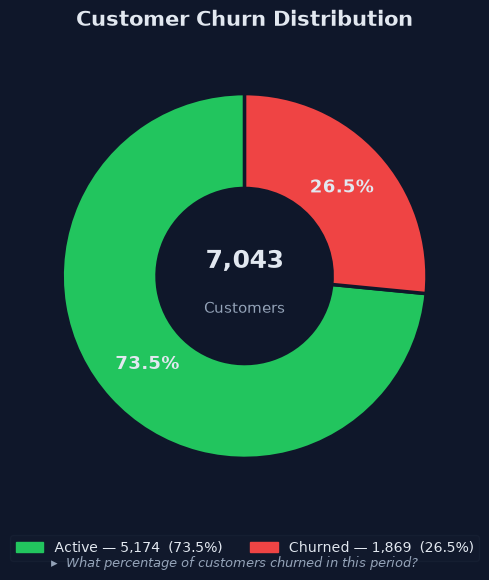

In [11]:
fig, cap = charts.chart_churn_distribution(df)
display(fig); plt.close(fig)

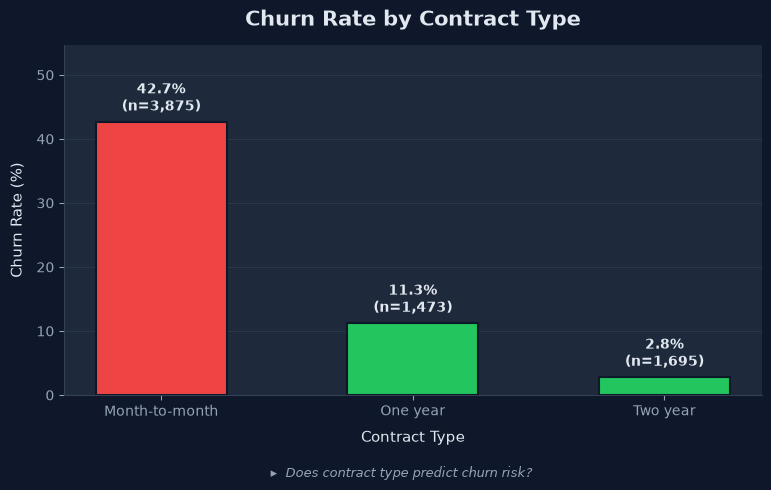

In [12]:
fig, cap = charts.chart_churn_by_contract(df)
display(fig); plt.close(fig)

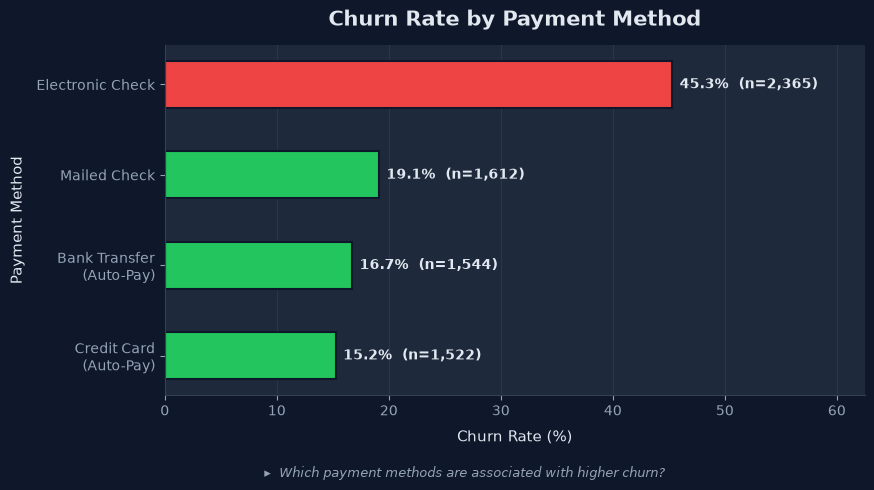

In [13]:
fig, cap = charts.chart_churn_by_payment_method(df)
display(fig); plt.close(fig)

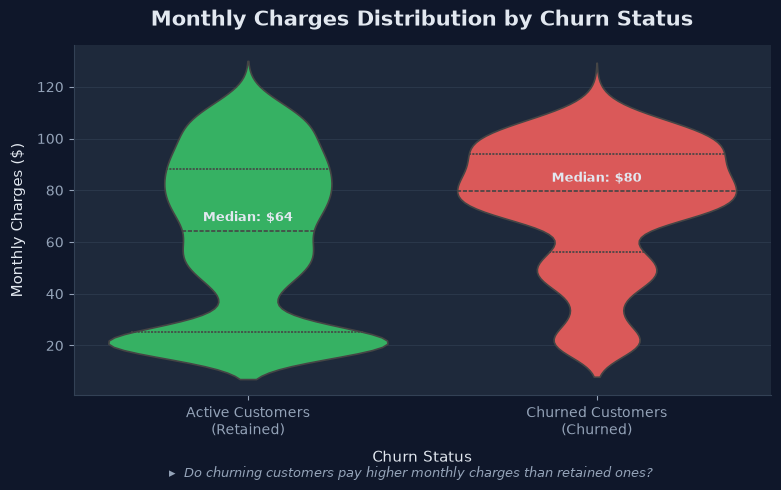

In [14]:
fig, cap = charts.chart_monthly_charges_by_churn(df)
display(fig); plt.close(fig)

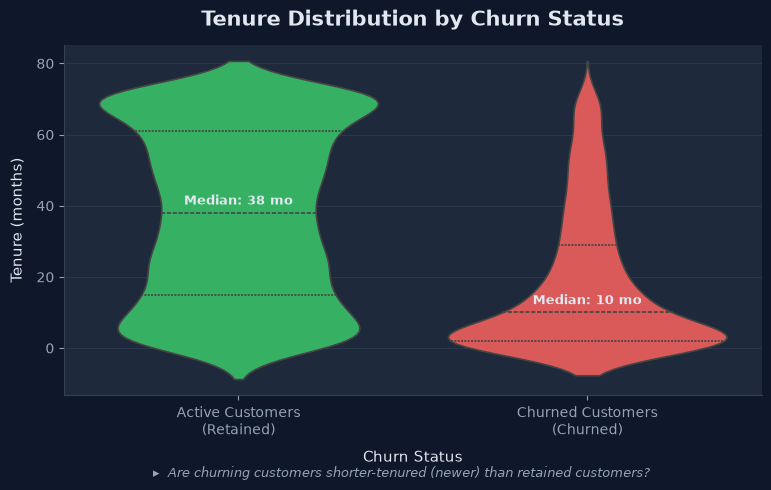

In [15]:
fig, cap = charts.chart_tenure_by_churn(df)
display(fig); plt.close(fig)

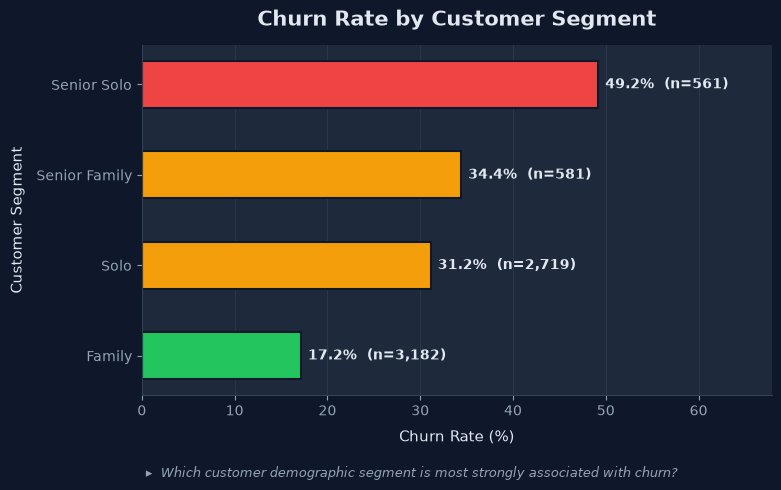

In [16]:
fig, cap = charts.chart_churn_by_segment(df)
display(fig); plt.close(fig)

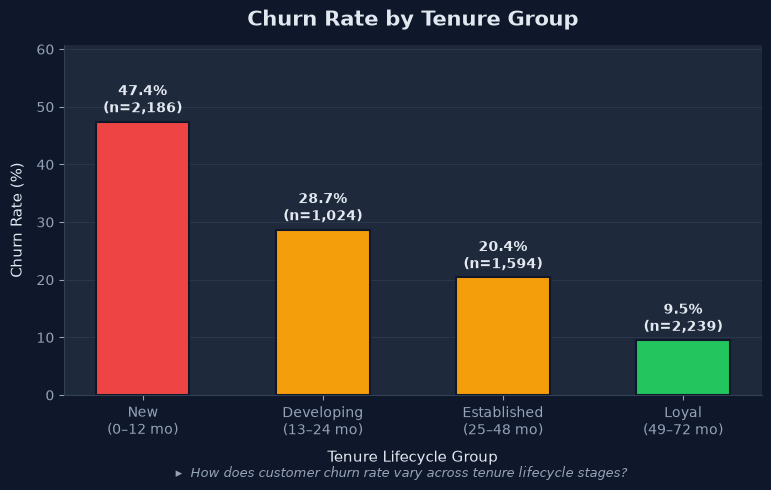

In [17]:
fig, cap = charts.chart_churn_by_tenure_group(df)
display(fig); plt.close(fig)

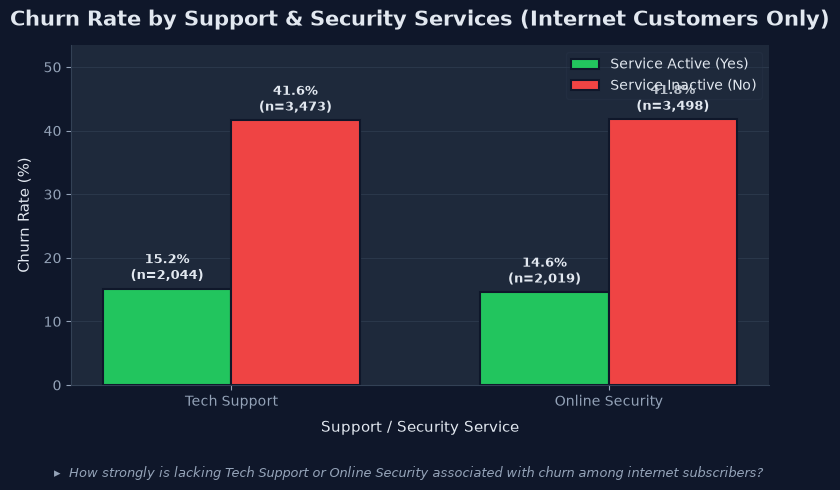

In [18]:
fig, cap = charts.chart_support_cols_by_churn(df)
display(fig); plt.close(fig)

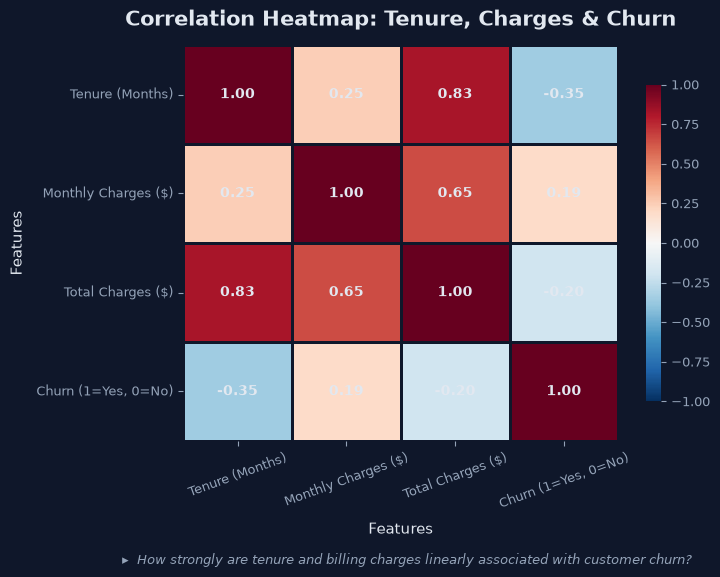

In [19]:
fig, cap = charts.chart_correlation_heatmap(df)
display(fig); plt.close(fig)

### 4.1 Checking the auto-pay caption

The auto-pay chart's caption says the auto-pay gap shrinks from about 13 points on month-to-month contracts to under 1 point on two-year contracts. That statement is a claim about the data, so this cell recomputes it directly.

In [20]:
tmp = df.copy()
tmp["Auto_Pay"] = tmp["PaymentMethod"].str.contains("automatic", case=False, na=False)

overall_ap = tmp.loc[tmp["Auto_Pay"], "Churn_Binary"].mean() * 100
overall_mp = tmp.loc[~tmp["Auto_Pay"], "Churn_Binary"].mean() * 100
print(f"Overall: auto-pay {overall_ap:.2f}%  manual {overall_mp:.2f}%  gap {overall_mp - overall_ap:.2f} pts")
print()

rows = []
for lvl, name in {0: "Month-to-month", 1: "One year", 2: "Two year"}.items():
    sub = tmp[tmp["Contract_Level"] == lvl]
    ap = sub.loc[sub["Auto_Pay"], "Churn_Binary"].mean() * 100
    mp = sub.loc[~sub["Auto_Pay"], "Churn_Binary"].mean() * 100
    rows.append({"Contract": name, "Auto-Pay %": round(ap, 2), "Manual %": round(mp, 2),
                 "Gap (pts)": round(mp - ap, 2)})
display(pd.DataFrame(rows).set_index("Contract"))

Overall: auto-pay 15.98%  manual 34.67%  gap 18.69 pts



,Auto-Pay %,Manual %,Gap (pts)
Contract,,,
Month-to-month,33.48,46.52,13.04
One year,10.01,12.72,2.71
Two year,2.79,2.91,0.11


**Interpretation.** Customers who pay by automatic method churn less than manual payers overall. Most of that difference comes from contract type: month-to-month customers are more likely to be on manual payment methods and also more likely to churn. The within-contract gaps in the table above show how much of the difference is left once contract is held fixed.

## 5. Model Training and Evaluation (Task 5)

### 5.1 Stratified split and preprocessing

The data is split 80/20 with stratification on the target, using `random_state=42`. The split is fitted on training data only. The same split is reused for all four models so they can be compared fairly.

In [21]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

df_model = df.copy()
for col in df_model.select_dtypes(include=["Int64"]).columns:
    df_model[col] = df_model[col].astype(float)

y = df_model["Churn_Binary"].astype(int)
drop_cols = ["customerID", "Churn", "Churn_Binary"]
X = df_model.drop(columns=[c for c in drop_cols if c in df_model.columns])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Churn rate train: {y_train.mean()*100:.2f}%  test: {y_test.mean()*100:.2f}%")

num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()
print(f"Numeric features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ]
)

Train: (5634, 27)  Test: (1409, 27)
Churn rate train: 26.54%  test: 26.54%
Numeric features (8): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract_Level', 'Unprotected_Services_Count', 'has_internet', 'Customer_Value']
Categorical features (19): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Tenure_Group', 'Monthly_Charge_Group', 'Customer_Segment', 'Payment_Risk']


### 5.2 Four classifiers

The four models are Logistic Regression, KNN, Decision Tree, and Random Forest. Each is wrapped in the same preprocessing pipeline and evaluated on the same held-out test set.

In [22]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=15),
    "DecisionTreeClassifier": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42),
    "RandomForestClassifier": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
}

trained, records = {}, []
for name, clf in models.items():
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, y_pred)
    trained[name] = pipe
    records.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_prob), 4),
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]), "FN": int(cm[1, 0]), "TP": int(cm[1, 1]),
    })

metrics_df = (
    pd.DataFrame(records)
    .sort_values(by=["ROC_AUC", "Recall"], ascending=[False, False])
    .reset_index(drop=True)
)
print("Model comparison (sorted by ROC-AUC, then Recall):")
display(metrics_df)

Model comparison (sorted by ROC-AUC, then Recall):


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,RandomForestClassifier,0.8041,0.6655,0.5267,0.5881,0.8440,936,99,177,197
1,LogisticRegression,0.7970,0.6457,0.5214,0.5769,0.8427,928,107,179,195
2,DecisionTreeClassifier,0.7970,0.6679,0.4679,0.5503,0.8383,948,87,199,175
3,KNeighborsClassifier,0.7779,0.5831,0.5722,0.5776,0.8217,882,153,160,214


### 5.3 Consistency check against the saved metrics

The app reads `models/metrics.csv`, which was produced by `utils/train_model.py`. This cell confirms the notebook reproduces those values.

In [23]:
saved = pd.read_csv(os.path.join(PROJECT_ROOT, "models", "metrics.csv"))
cmp_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "TN", "FP", "FN", "TP"]
diff = (
    metrics_df.set_index("Model")[cmp_cols].astype(float)
    - saved.set_index("Model").loc[metrics_df["Model"], cmp_cols].astype(float)
).abs()
print("Largest absolute difference per model vs saved metrics.csv:")
print(diff.max(axis=1).round(6).to_string())

Largest absolute difference per model vs saved metrics.csv:
Model
RandomForestClassifier    0.0
LogisticRegression        0.0
DecisionTreeClassifier    0.0
KNeighborsClassifier      1.0


**Reproducibility note.** The selected Random Forest matches the saved `metrics.csv` exactly. The KNN row differs by one test-set prediction (one customer moves between the false-negative and true-positive counts). That single case does not change the model comparison or the selection, and it was not traced further. Other models match.

**Interpretation.** The models are close on ROC-AUC, so the choice depends on recall and the business trade-off. Random Forest is selected by the same rule as `train_model.py`: highest ROC-AUC, with recall as the tie-breaker. The selected model is then evaluated in more detail below.

### 5.4 Selected model: confusion matrix and classification report

In [24]:
best_name = metrics_df.iloc[0]["Model"]
best_pipe = trained[best_name]
print(f"Selected model: {best_name}")

y_pred_test = best_pipe.predict(X_test)
y_prob_test = best_pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred_test)
cm_df = pd.DataFrame(
    cm,
    index=["Actual Retained", "Actual Churned"],
    columns=["Predicted Retained", "Predicted Churned"],
)
display(cm_df)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_test, target_names=["Retained", "Churned"], digits=3))

Selected model: RandomForestClassifier


,Predicted Retained,Predicted Churned
Actual Retained,936,99
Actual Churned,177,197


              precision    recall  f1-score   support

    Retained      0.841     0.904     0.872      1035
     Churned      0.666     0.527     0.588       374

    accuracy                          0.804      1409
   macro avg      0.753     0.716     0.730      1409
weighted avg      0.794     0.804     0.796      1409



### 5.5 ROC and precision-recall curves (test set)

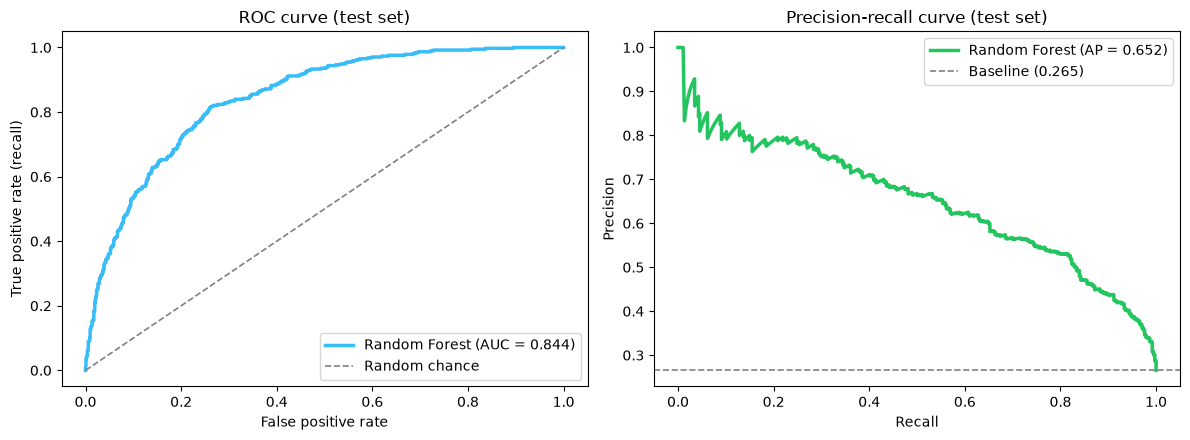

In [25]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
prec, rec, _ = precision_recall_curve(y_test, y_prob_test)
roc_auc_val = auc(fpr, tpr)
ap = average_precision_score(y_test, y_prob_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#38bdf8", lw=2.5, label=f"Random Forest (AUC = {roc_auc_val:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1.2, label="Random chance")
axes[0].set_title("ROC curve (test set)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend()

axes[1].plot(rec, prec, color="#22c55e", lw=2.5, label=f"Random Forest (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), ls="--", color="grey", lw=1.2, label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_title("Precision-recall curve (test set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.6 Feature importances

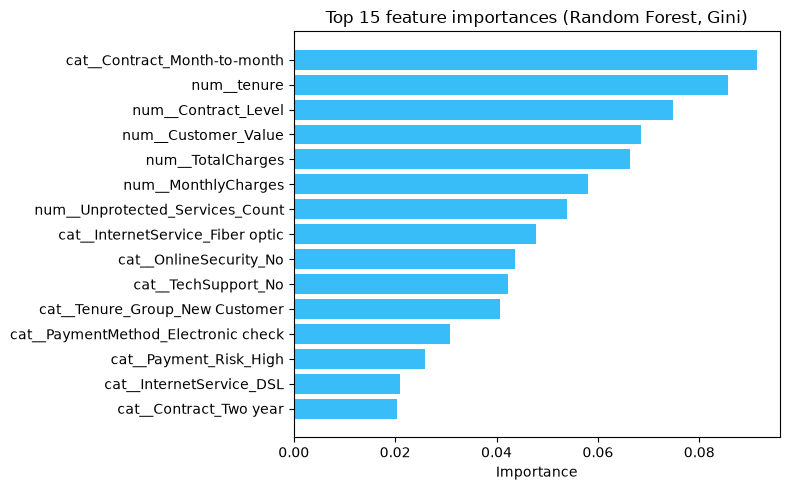

In [26]:
feat_names = best_pipe[:-1].get_feature_names_out()
importances = best_pipe.named_steps["classifier"].feature_importances_
fi = (
    pd.DataFrame({"Feature": feat_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(15)
    .sort_values("Importance")
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fi["Feature"], fi["Importance"], color="#38bdf8")
ax.set_title("Top 15 feature importances (Random Forest, Gini)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

**Interpretation.** Feature importance measures how much the model relies on a feature to make predictions. It does not show that the feature causes churn. The top features are the ones the model uses most. Treat them as associations.

## 6. Retention Scoring (Held-out Test Set)

The retention dashboard uses the trained model to estimate churn probability for each customer, then multiplies by monthly charges to get expected monthly revenue at risk.

**Important.** The model was trained on the 80% training split, so scoring all 7,043 customers mixes in customers the model has already seen. Those scores can be optimistic. This section reports the figures on the 20% held-out test set, then checks whether the all-customer scoring differs materially.

In [27]:
def risk_tier(p):
    return np.select(
        [p < 0.25, p < 0.50, p < 0.75],
        ["Low", "Medium", "High"],
        default="Critical",
    )

test_scored = pd.DataFrame({
    "Churn_Probability": y_prob_test,
    "MonthlyCharges": X_test["MonthlyCharges"].to_numpy(),
    "Churn_Binary": y_test.to_numpy(),
})
test_scored["Expected_Rev_Risk"] = test_scored["MonthlyCharges"] * test_scored["Churn_Probability"]
test_scored["Risk_Level"] = risk_tier(test_scored["Churn_Probability"])

tier_summary = (
    test_scored.groupby("Risk_Level")
    .agg(
        Customers=("Churn_Binary", "size"),
        Actual_Churn_Rate=("Churn_Binary", "mean"),
        Expected_Monthly_Rev_Risk=("Expected_Rev_Risk", "sum"),
    )
    .reindex(["Low", "Medium", "High", "Critical"])
)
tier_summary["Actual_Churn_Rate"] = (tier_summary["Actual_Churn_Rate"] * 100).round(2)
tier_summary["Expected_Monthly_Rev_Risk"] = tier_summary["Expected_Monthly_Rev_Risk"].round(2)
print("Held-out test set: risk tiers")
display(tier_summary)

Held-out test set: risk tiers


,Customers,Actual_Churn_Rate,Expected_Monthly_Rev_Risk
Risk_Level,,,
Low,809,8.16,4806.21
Medium,304,36.51,7942.30
High,229,62.88,10513.72
Critical,67,79.10,4515.81


**Calibration check.** The `Actual_Churn_Rate` column shows the observed churn rate in each tier. If the tiers are well calibrated, that rate should rise from Low to Critical and should be roughly in line with the probability band. Large gaps mean the probabilities are over- or under-confident.

### 6.1 Held-out vs all-customer scoring

In [28]:
all_probs = best_pipe.predict_proba(X)[:, 1]
all_scored = pd.DataFrame({
    "Churn_Probability": all_probs,
    "MonthlyCharges": X["MonthlyCharges"].to_numpy(),
    "Churn_Binary": y.to_numpy(),
})
all_scored["Expected_Rev_Risk"] = all_scored["MonthlyCharges"] * all_scored["Churn_Probability"]

def summarize(frame, label):
    hr = frame[frame["Churn_Probability"] >= 0.50]
    return {
        "Scope": label,
        "Customers scored": len(frame),
        "High+Critical share (%)": round(len(hr) / len(frame) * 100, 2),
        "Predicted churn in High+Critical (%)": round(hr["Churn_Probability"].mean() * 100, 2),
        "Observed churn in High+Critical (%)": round(hr["Churn_Binary"].mean() * 100, 2),
        "Expected monthly revenue at risk per customer ($)": round(hr["Expected_Rev_Risk"].sum() / len(frame), 2),
    }

comparison = pd.DataFrame([
    summarize(test_scored, "Held-out test set (20%)"),
    summarize(all_scored, "All customers (includes training data)"),
])
display(comparison.set_index("Scope").T)

Scope,Held-out test set (20%),All customers (includes training data)
Customers scored,1409.00,7043.00
High+Critical share (%),21.01,20.97
Predicted churn in High+Critical (%),65.02,65.49
Observed churn in High+Critical (%),66.55,72.11
Expected monthly revenue at risk per customer ($),10.67,10.85


**Interpretation.** The two rows are compared on rates and per-customer values, because the all-customer total is simply about five times larger. The share of customers flagged High+Critical is almost identical in both scopes. The useful check is calibration on the training data: if the model were overfitting, the observed churn rate in the High+Critical group would be much higher on training customers than the predicted rate. Compare the predicted and observed columns in each row to see whether that happened. The held-out row remains the figure to report as out-of-sample performance.

## 7. Limitations and Data Gaps

**Missing rubric fields.** The following fields were requested in the assignment but do not exist in this dataset, so the project does not use them:

| Requested field | Status in this dataset |
|---|---|
| Satisfaction score / NPS | Not available |
| Complaints, support tickets | Not available. `TechSupport` is used as the nearest support indicator |
| Late payments | Not available. `PaymentMethod` and `PaperlessBilling` are used as proxies |
| Referral count | Not available |
| Region | Not available |
| Last interaction date | Not available |
| Subscription type | Not available. `Contract` is the closest equivalent |

These omissions are a deliberate and documented choice, not an oversight. No values were invented for them.

**Association, not causation.** The model identifies patterns in historical data. A high-risk score does not show that a service, price, or contract causes a customer to leave. Retention actions should be tested with a controlled experiment before their effect is assumed.

**Single snapshot.** The data is one point in time with no history of how a customer's status changed. The model cannot account for trends.

**Scoring on training data.** The dashboard currently scores all customers, so its risk figures include the 80% the model was trained on. Section 6 measures how much that changes the picture. The held-out split is the appropriate basis for out-of-sample claims.

## 8. Summary

**Model performance (held-out test set, n = 1,409).** Random Forest was selected with ROC-AUC 0.844. At the default 0.50 threshold it has accuracy 0.804, precision 0.666, and recall 0.527. It catches about half of churners, and about two-thirds of the customers it flags are true churners. Accuracy is the least informative of these numbers because of the 26.5% churn rate.

**Retention exposure.** On the held-out set, 21.0% of customers are High or Critical risk. Actual churn rises steadily across the risk tiers, from 8.2% (Low) to 36.5% (Medium), 62.9% (High), and 79.1% (Critical), which suggests the probabilities are usefully calibrated. Among High+Critical customers, predicted churn is 65.0% and observed churn is 66.6%, so the probabilities are close to the observed rates.

**Auto-pay caption.** The auto-pay chart's caption is correct: the gap is 13.0 points on month-to-month contracts, 2.7 on one-year, and 0.1 on two-year contracts. Contract type explains most of the overall auto-pay difference.

**Scoring on training data.** The check in Section 6 found little optimism for this model. The share of customers flagged High+Critical is nearly the same on the full dataset (21.0%) as on the held-out set, and observed churn among flagged training customers (72.1%) is slightly higher than predicted (65.5%). The held-out figures are still the ones to cite as out-of-sample results.

**Caveat.** These are associations from one snapshot. The model does not show that any service, price, or contract causes churn, and retention actions should be tested with a controlled experiment before their effect is assumed.